# Install Dependencies

In [ ]:
# !pip install segmentation-models-pytorch albumentations opencv-python

# Imports

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn

import albumentations as A

import segmentation_models_pytorch as smp

# Dataset Paths

In [ ]:
# --- Mount Drive ---
from google.colab import drive
drive.mount('/content/drive')

#GET DATASET
IMAGE_DIR = "/content/drive/MyDrive/aura-X/datasets/cracks_with_mask_dataset/images"
MASK_DIR = "/content/drive/MyDrive/aura-X/cracks_with_mask_dataset/masks"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Creating Dataset (Class)

In [ ]:
class CrackDataset(Dataset):

    def __init__(self, image_paths, mask_paths):

        self.image_paths = image_paths
        self.mask_paths = mask_paths

        self.transform = A.Compose([
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(
            self.mask_paths[idx],
            cv2.IMREAD_GRAYSCALE
        )

        augmented = self.transform(
            image=image,
            mask=mask
        )

        image = augmented["image"]
        mask = augmented["mask"]

        image = image.astype(np.float32) / 255.0

        mask = (mask > 0).astype(np.float32)

        image = torch.tensor(
            image.transpose(2, 0, 1),
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0)

        return image, mask

# Loading Files

In [ ]:
image_files = sorted([
    os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
])

mask_files = sorted([
    os.path.join(MASK_DIR, f)
    for f in os.listdir(MASK_DIR)
])

print("Images:", len(image_files))
print("Masks:", len(mask_files))

Images: 800
Masks: 800


# Train/Validation Split

In [ ]:
train_images, val_images, train_masks, val_masks = train_test_split(
    image_files,
    mask_files,
    test_size=0.2,
    random_state=42
)

# Dataloaders

In [ ]:
train_dataset = CrackDataset(
    train_images,
    train_masks
)

val_dataset = CrackDataset(
    val_images,
    val_masks
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

# Creating the U-Net Model

In [ ]:
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1
)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

In [ ]:
#Moving device to GPU
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = model.to(device)

In [ ]:
device

device(type='cuda')

# Loss Function

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

Let's inspect a few samples and verify:

- The masks align with the cracks.
- The masks are not completely black.
- The masks are binary (crack vs background).

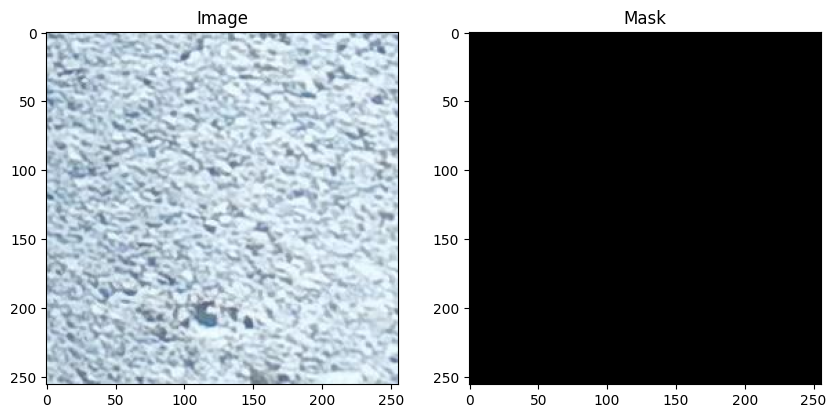

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(image_files[0])
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

mask = cv2.imread(
    mask_files[0],
    cv2.IMREAD_GRAYSCALE
)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title("Image")

plt.subplot(1,2,2)
plt.imshow(mask, cmap="gray")
plt.title("Mask")

plt.show()

In [ ]:
import numpy as np

mask = cv2.imread(
    mask_files[0],
    cv2.IMREAD_GRAYSCALE
)

print(np.unique(mask))

[0]


# Scanning the entire dataset for inspection.

In [ ]:
import cv2
import numpy as np

positive_masks = 0
empty_masks = 0

for mask_path in mask_files:

    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if np.max(mask) > 0:
        positive_masks += 1
    else:
        empty_masks += 1

print("Positive Masks:", positive_masks)
print("Empty Masks:", empty_masks)

Positive Masks: 504
Empty Masks: 296


This is actually a very good output. This means we have `63% Positive Samples and 37% Negative Samples.` For a crack segmentation dataset, it's completely reasonable.
**In Conclusion:**
- The dataset is NOT corrupted
- The masks are valid
- U-Net training is worth continuing
- We have enough positive samples to learn crack patterns

This also tells us that the first image-mask pair we opened earlier was simply one of the 296 negative samples, that's why: `np.unique(mask)` returned: `[0]` because no crack existed in that image.

# One more quick Validation

In [ ]:
#Find a positive sample and visualize it
import cv2
import numpy as np
import matplotlib.pyplot as plt

for idx, mask_path in enumerate(mask_files):

    mask = cv2.imread(
        mask_path,
        cv2.IMREAD_GRAYSCALE
    )

    if np.max(mask) > 0:

        img = cv2.imread(image_files[idx])
        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        plt.figure(figsize=(10,5))

        plt.subplot(1,2,1)
        plt.imshow(img)
        plt.title("Image")

        plt.subplot(1,2,2)
        plt.imshow(mask, cmap="gray")
        plt.title("Positive Mask")

        plt.show()

        break

This confirms that the crack annotations visually align with the image.

# Dice Score Function

In [ ]:
import torch


def dice_score(preds, targets, smooth=1e-6):

    preds = torch.sigmoid(preds)
    preds = (preds > 0.5).float()

    intersection = (preds * targets).sum()

    dice = (
        2.0 * intersection + smooth
    ) / (
        preds.sum() + targets.sum() + smooth
    )

    return dice.item()

# Training Loop

In [ ]:
!pip install tqdm

In [ ]:
# from tqdm.auto import tqdm

# EPOCHS = 20

# for epoch in range(EPOCHS):

#     model.train()

#     train_loss = 0

#     progress_bar = tqdm(
#         train_loader,
#         desc=f"Epoch {epoch+1}/{EPOCHS}"
#     )

#     for images, masks in progress_bar:

#         images = images.to(device)
#         masks = masks.to(device)

#         optimizer.zero_grad()

#         outputs = model(images)

#         loss = loss_fn(outputs, masks)

#         loss.backward()

#         optimizer.step()

#         train_loss += loss.item()

#         progress_bar.set_postfix(
#             loss=f"{loss.item():.4f}"
#         )

#     avg_loss = train_loss / len(train_loader)

#     print(
#         f"\nEpoch [{epoch+1}/{EPOCHS}] "
#         f"Average Loss: {avg_loss:.4f}\n"
#     )

In [ ]:
from tqdm.auto import tqdm

EPOCHS = 20

best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "dice_score": []
}

for epoch in range(EPOCHS):

    ###################################
    # TRAINING
    ###################################

    model.train()

    train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} [TRAIN]"
    )

    for images, masks in train_bar:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = loss_fn(outputs, masks)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = train_loss / len(train_loader)

    ###################################
    # VALIDATION
    ###################################

    model.eval()

    val_loss = 0.0
    dice_total = 0.0

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS} [VAL]"
    )

    with torch.no_grad():

        for images, masks in val_bar:

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            loss = loss_fn(outputs, masks)

            val_loss += loss.item()

            dice_total += dice_score(
                outputs,
                masks
            )

            val_bar.set_postfix(
                val_loss=f"{loss.item():.4f}"
            )

    avg_val_loss = val_loss / len(val_loader)

    avg_dice = dice_total / len(val_loader)

    ###################################
    # HISTORY
    ###################################

    history["train_loss"].append(
        avg_train_loss
    )

    history["val_loss"].append(
        avg_val_loss
    )

    history["dice_score"].append(
        avg_dice
    )

    ###################################
    # SAVE BEST MODEL
    ###################################

    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "best_unet_model.pth"
        )

        print(
            "\nBest model saved!\n"
        )

    ###################################
    # EPOCH SUMMARY
    ###################################

    print(
        f"\nEpoch [{epoch+1}/{EPOCHS}]"
    )

    print(
        f"Train Loss : {avg_train_loss:.4f}"
    )

    print(
        f"Val Loss   : {avg_val_loss:.4f}"
    )

    print(
        f"Dice Score : {avg_dice:.4f}"
    )

    print("-" * 50)

Epoch 1/20 [TRAIN]:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 1/20 [VAL]:   0%|          | 0/20 [00:00<?, ?it/s]


Best model saved!


Epoch [1/20]
Train Loss : 0.8477
Val Loss   : 0.6840
Dice Score : 0.0292
--------------------------------------------------


Epoch 2/20 [TRAIN]:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 2/20 [VAL]:   0%|          | 0/20 [00:00<?, ?it/s]

...

Epoch 19/20 [VAL]:   0%|          | 0/20 [00:00<?, ?it/s]


Best model saved!


Epoch [19/20]
Train Loss : 0.0366
Val Loss   : 0.0353
Dice Score : 0.8252
--------------------------------------------------


Epoch 20/20 [TRAIN]:   0%|          | 0/80 [00:00<?, ?it/s]

Epoch 20/20 [VAL]:   0%|          | 0/20 [00:00<?, ?it/s]


Best model saved!


Epoch [20/20]
Train Loss : 0.0334
Val Loss   : 0.0322
Dice Score : 0.8293
--------------------------------------------------


#Saving the Model

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

SAVE_DIR = "/content/drive/MyDrive/aura-X/models/cracks_with_label"

os.makedirs(SAVE_DIR, exist_ok=True)

In [ ]:
# Save using the best model checkpoint
torch.save(
    model.state_dict(),
    f"{SAVE_DIR}/unet_crack_baseline_v1.pth"
)

print("Model saved successfully.")

Model saved successfully.


In [ ]:
# torch.save(
#     model.state_dict(),
#     "unet_crack_baseline_v1.pth"
# )

In [ ]:
#Saving the full model
torch.save(
    model,
    f"{SAVE_DIR}/unet_crack_baseline_full.pt"
)

# Saving Training Metrics

In [ ]:
import json

metrics = {
    "epochs": 20,
    "train_loss": 0.0334,
    "val_loss": 0.0322,
    "dice_score": 0.8293
}

with open(
    f"{SAVE_DIR}/baseline_metrics.json",
    "w"
) as f:
    json.dump(metrics, f, indent=4)

# Visualizing Predictions

# Plotting Training Curves

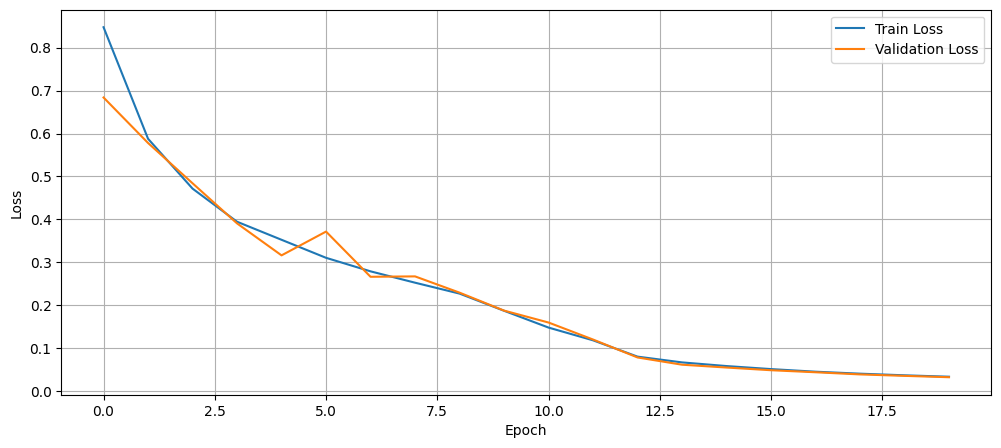

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

**Generating Random Predictions**

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load Saved Model
import segmentation_models_pytorch as smp
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1
)

model.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/aura-X/models/cracks_with_label/unet_crack_baseline_v1.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Model loaded successfully.")

Model loaded successfully.


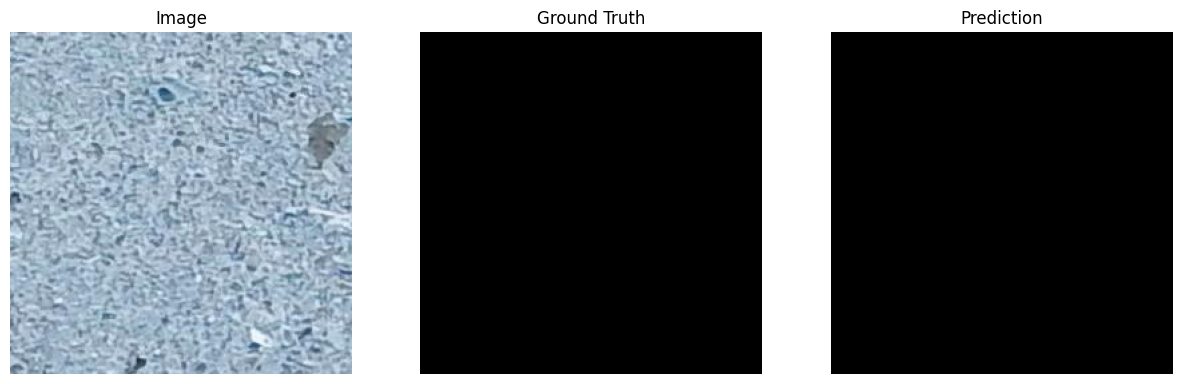

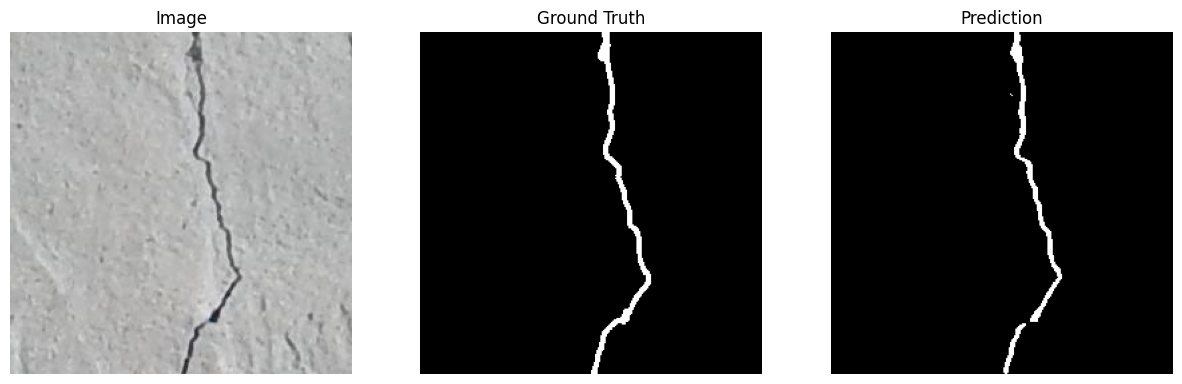

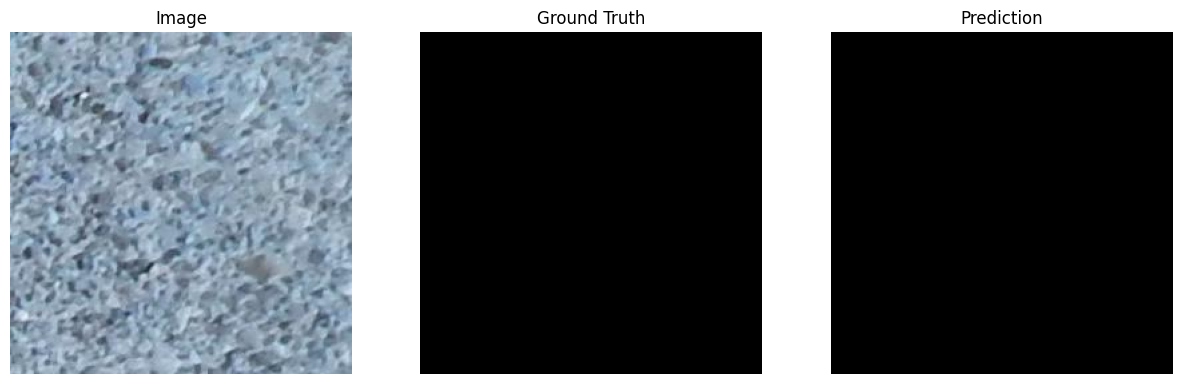

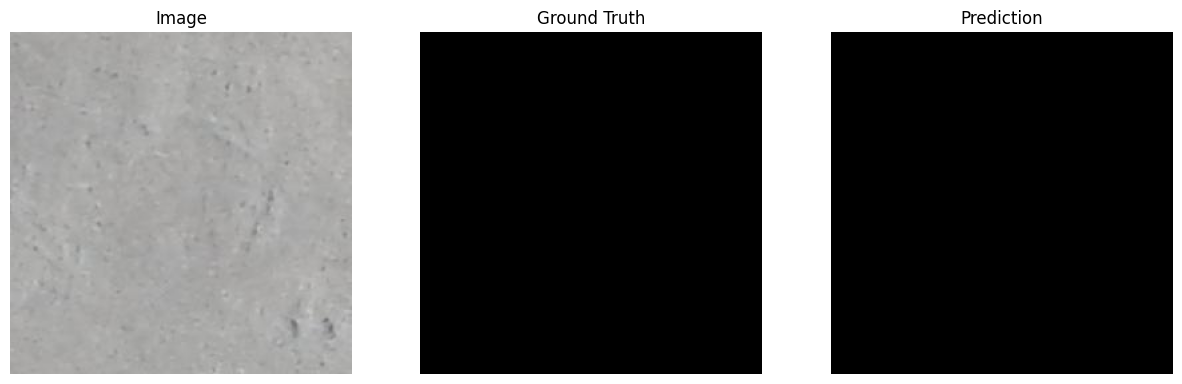

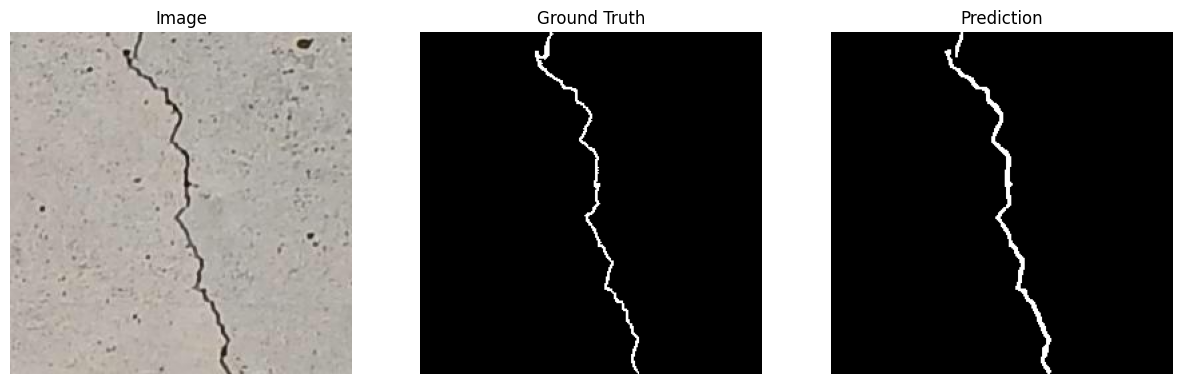

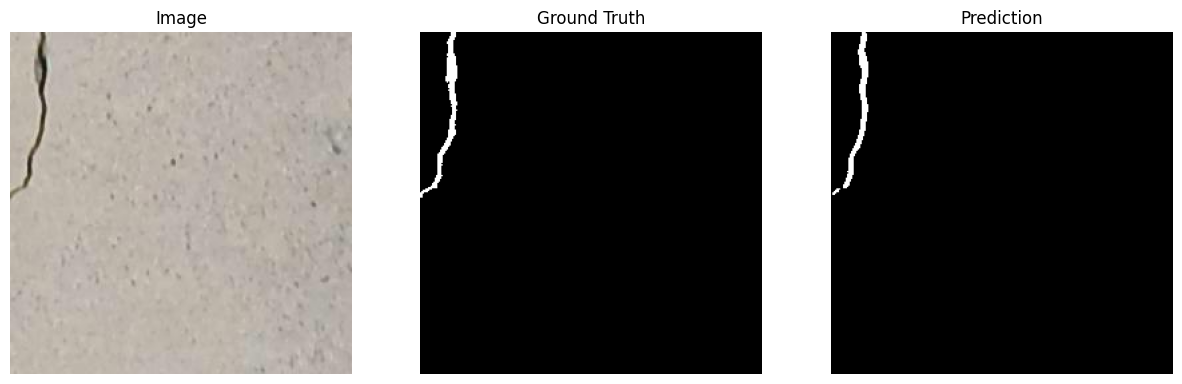

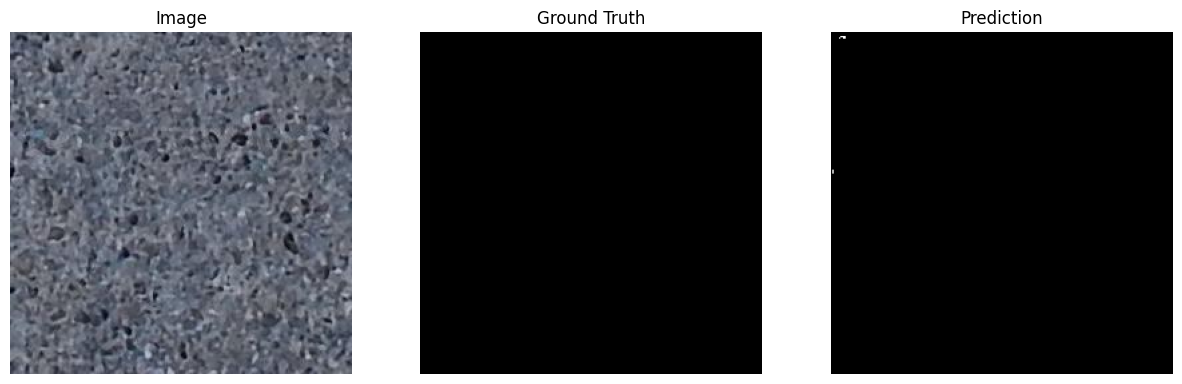

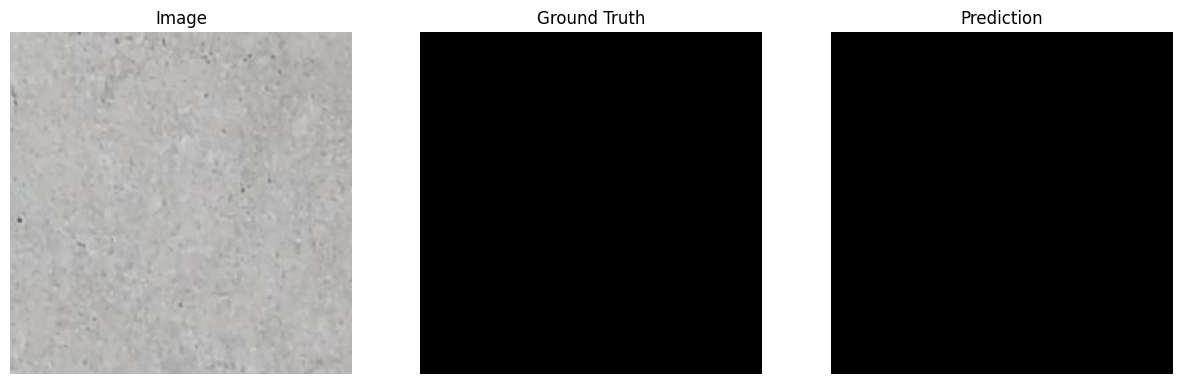

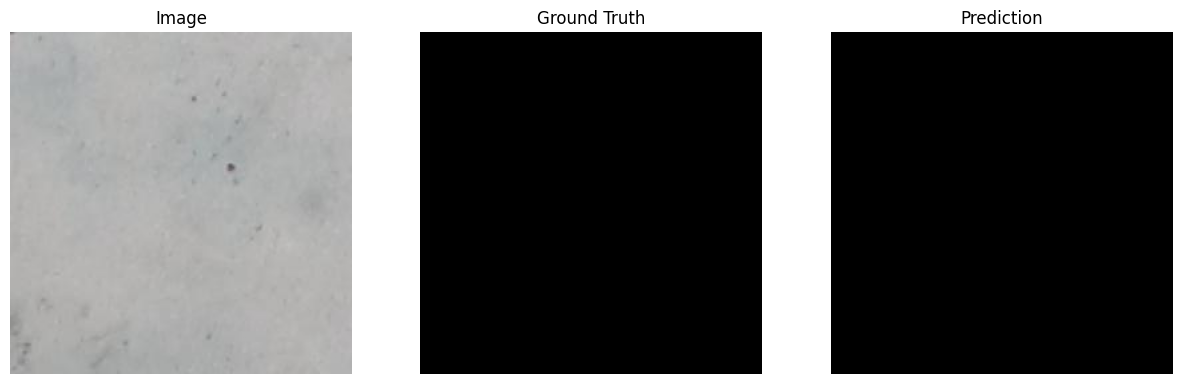

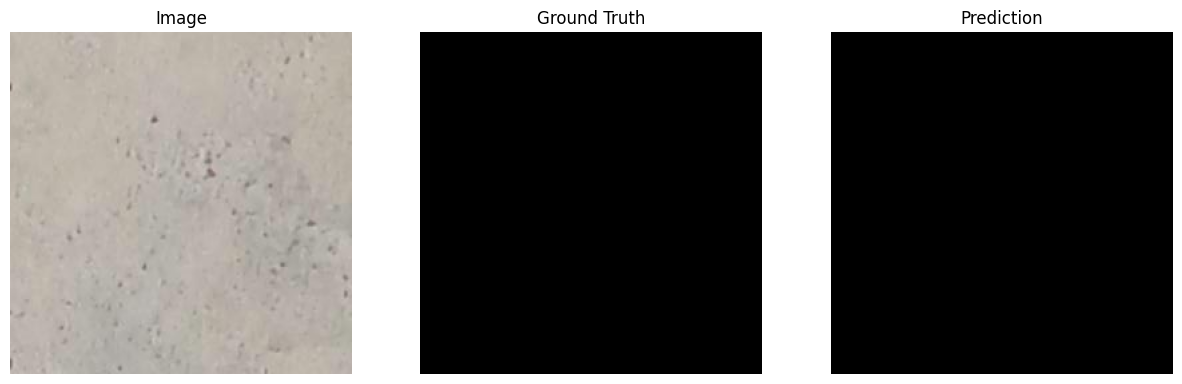

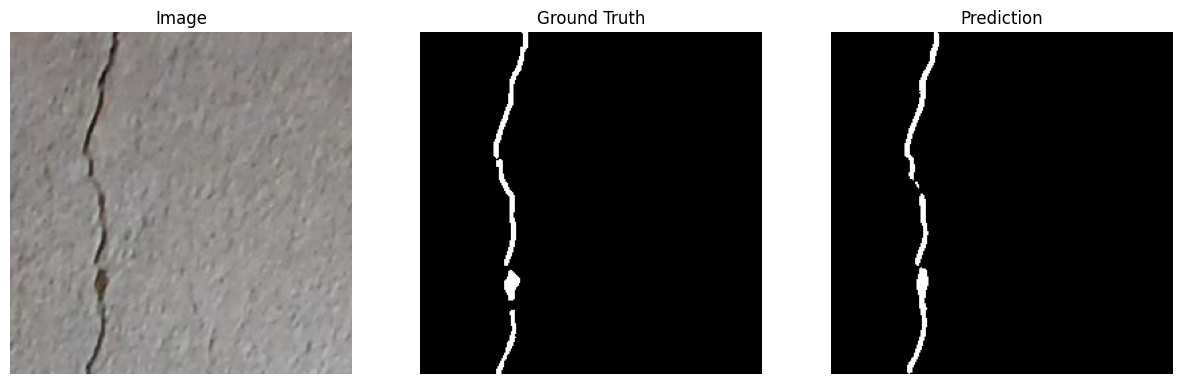

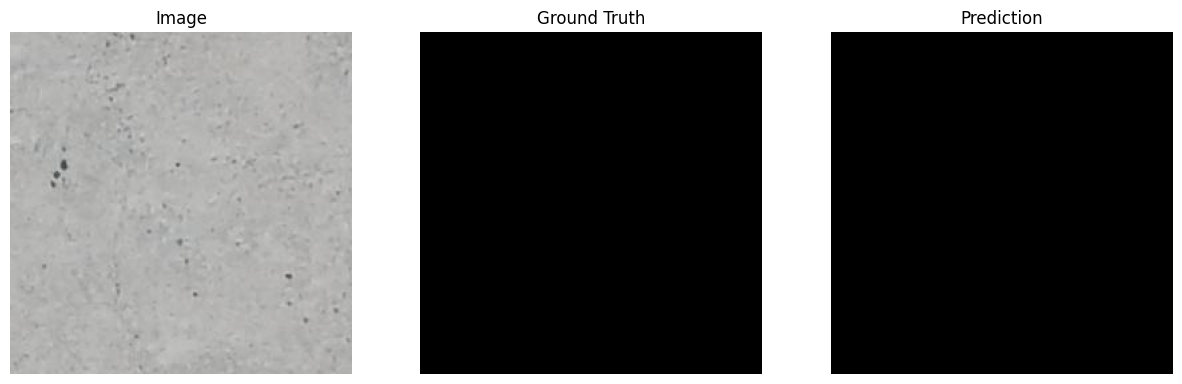

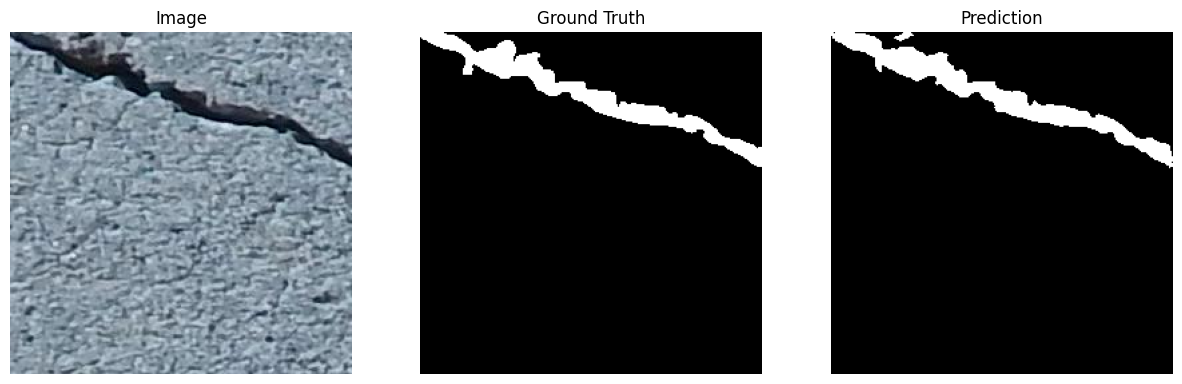

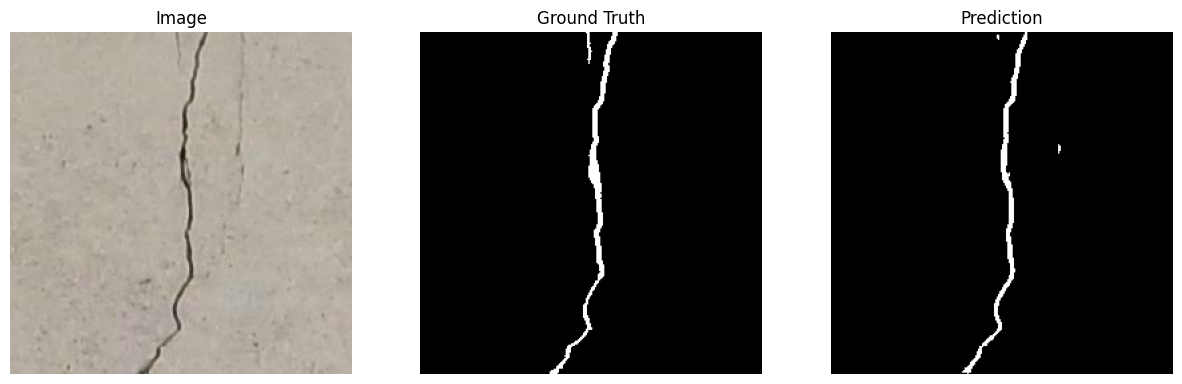

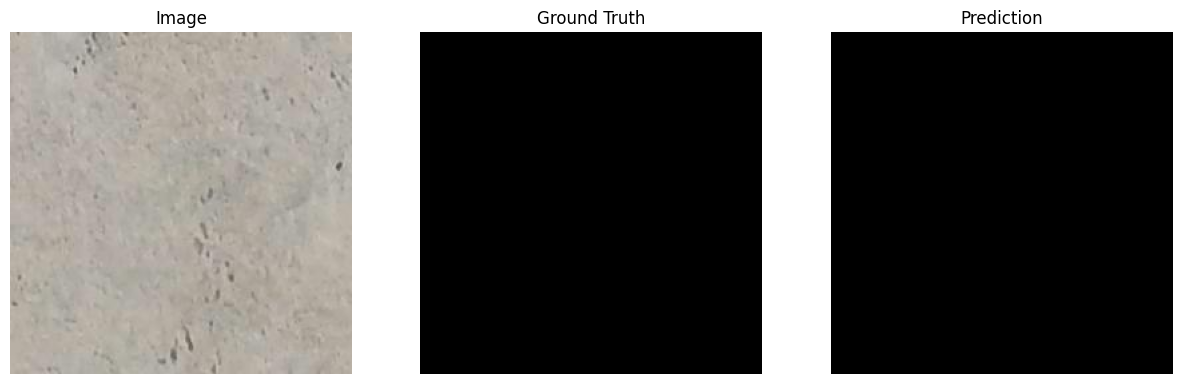

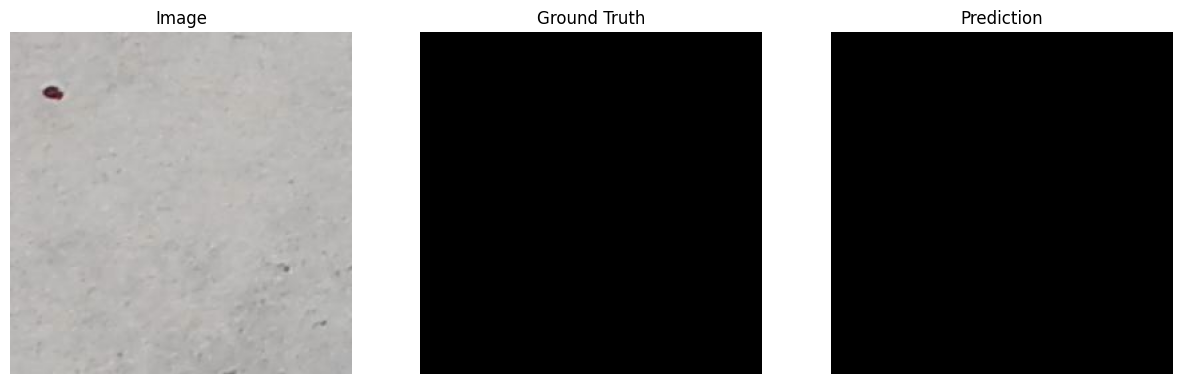

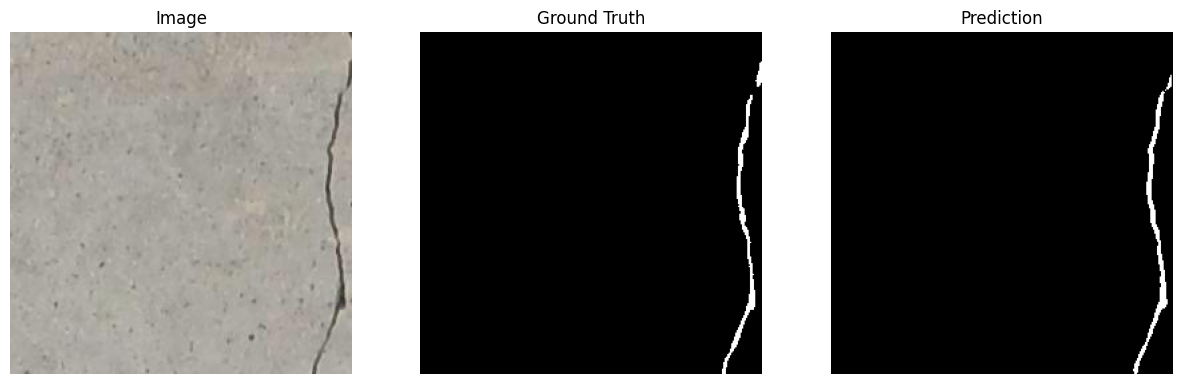

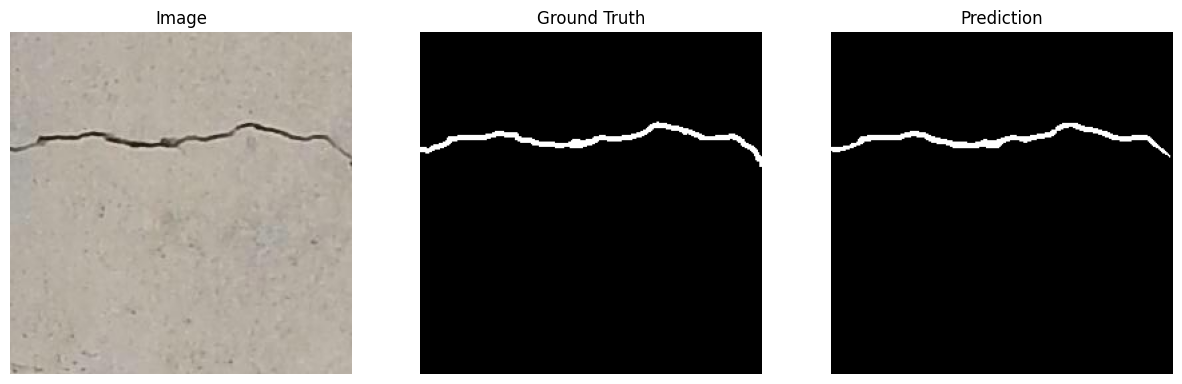

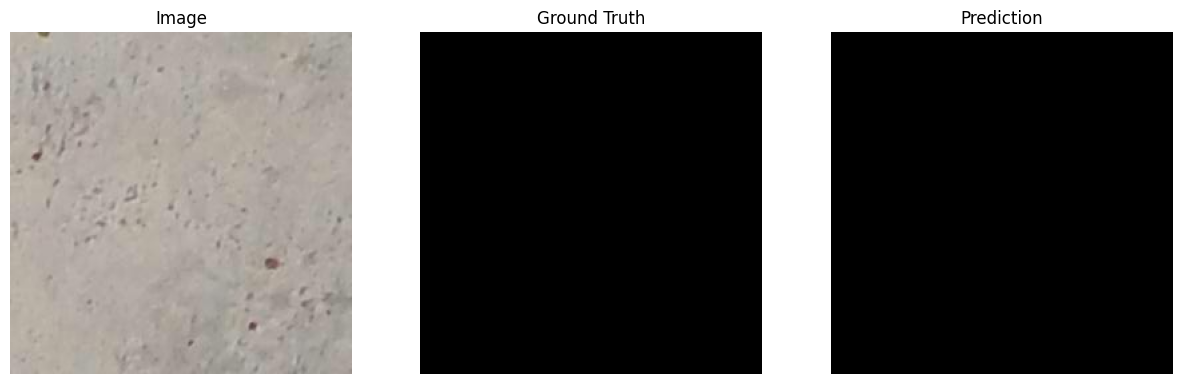

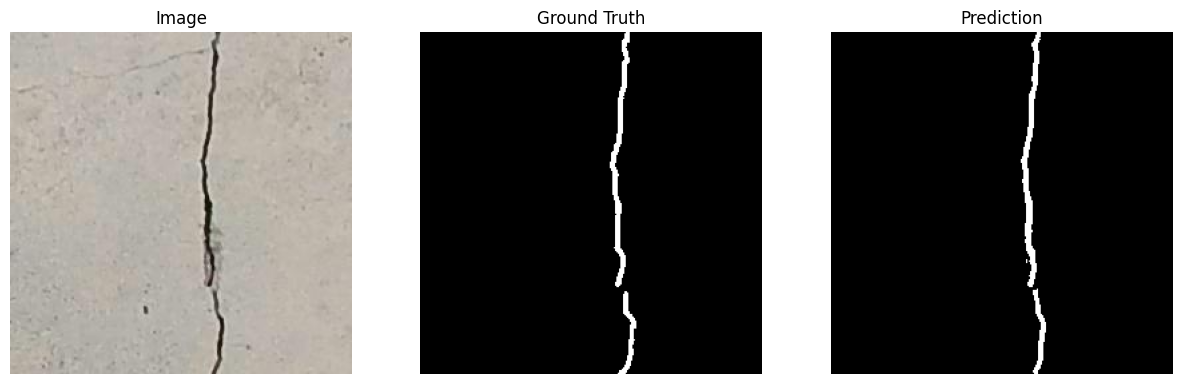

In [ ]:
# Show 20 Random Predictions
import random
import matplotlib.pyplot as plt
import cv2
import numpy as np
import torch

indices = random.sample(
    range(len(val_dataset)),
    20
)

for idx in indices:

    image, mask = val_dataset[idx]

    with torch.no_grad():

        pred = model(
            image.unsqueeze(0).to(device)
        )

        pred = torch.sigmoid(pred)

        pred = (
            pred > 0.5
        ).float()

    image_np = (
        image.permute(1,2,0)
        .cpu()
        .numpy()
    )

    mask_np = (
        mask.squeeze()
        .cpu()
        .numpy()
    )

    pred_np = (
        pred.squeeze()
        .cpu()
        .numpy()
    )

    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(image_np)
    plt.title("Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(mask_np, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(pred_np, cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

    plt.show()

# Building pixel-level confusion matrix

In [ ]:
!pip install scikit-learn

In [ ]:
# Evaluating the entire Validation Set
from sklearn.metrics import confusion_matrix
import numpy as np

all_preds = []
all_targets = []

model.eval()

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)

        outputs = model(images)

        outputs = torch.sigmoid(outputs)

        outputs = (
            outputs > 0.5
        ).cpu().numpy()

        masks = masks.cpu().numpy()

        all_preds.extend(
            outputs.flatten()
        )

        all_targets.extend(
            masks.flatten()
        )

cm = confusion_matrix(
    all_targets,
    all_preds
)

print(cm)

[[10338583    18662]
 [   22478   106037]]


In [ ]:
# Getting the full metrics report
from sklearn.metrics import (
    classification_report
)

print(
    classification_report(
        all_targets,
        all_preds,
        target_names=[
            "background",
            "crack"
        ]
    )
)

              precision    recall  f1-score   support

  background       1.00      1.00      1.00  10357245
       crack       0.85      0.83      0.84    128515

    accuracy                           1.00  10485760
   macro avg       0.92      0.91      0.92  10485760
weighted avg       1.00      1.00      1.00  10485760



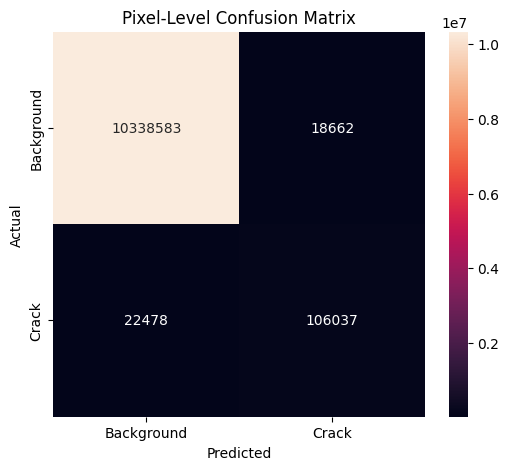

In [ ]:
#Visualizing confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Background",
        "Crack"
    ],
    yticklabels=[
        "Background",
        "Crack"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Pixel-Level Confusion Matrix")

plt.show()

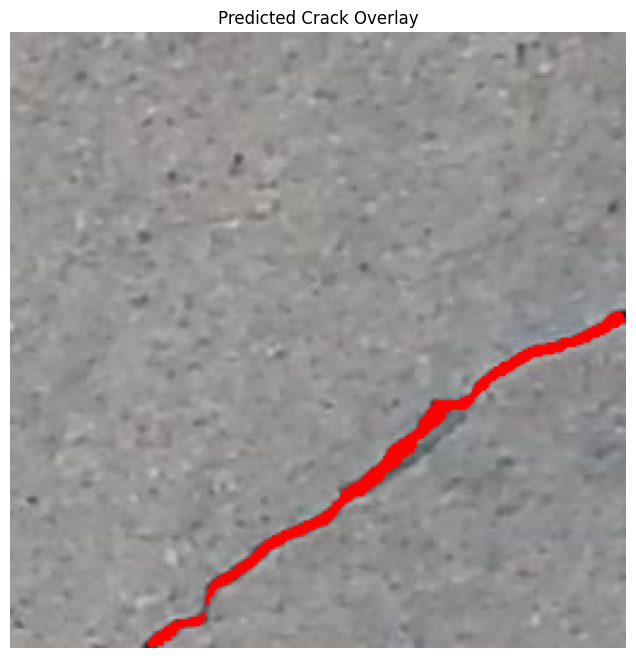

In [ ]:
# Creating an overlay Visualization
idx = random.randint(
    0,
    len(val_dataset)-1
)

image, mask = val_dataset[idx]

with torch.no_grad():

    pred = model(
        image.unsqueeze(0).to(device)
    )

    pred = (
        torch.sigmoid(pred)
        > 0.5
    ).float()

image_np = image.permute(
    1,2,0
).cpu().numpy()

pred_np = pred.squeeze().cpu().numpy()

overlay = image_np.copy()

overlay[pred_np == 1] = [1,0,0]

plt.figure(figsize=(8,8))
plt.imshow(overlay)
plt.title("Predicted Crack Overlay")
plt.axis("off")
plt.show()